Task5 -**Advanced Analysis**

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10, 6]

In [5]:
df = pd.read_csv("../dataset/Telco_Customer_Churn_Dataset_cleaned.csv")

In [6]:
bins = [-1, 12, 36, 100]
labels = ['0-12 months', '13-36 months', '+37 months']
df['tenure_group'] = pd.cut(df['tenure'], bins=bins, labels=labels)

In [7]:
print(df['tenure_group'].value_counts().sort_index())

tenure_group
0-12 months     2186
13-36 months    1856
+37 months      3001
Name: count, dtype: int64


Churn Analytics by gendre and eldest


---Churn by gender


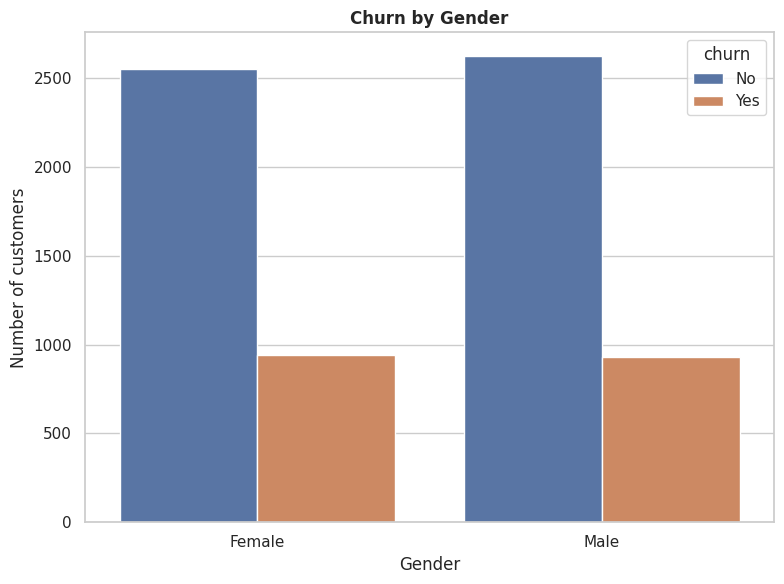

In [8]:
print('\n---Churn by gender')

fig, ax = plt.subplots(1,1, figsize=(8,6))
sns.countplot(data=df, x='gender', hue='churn', ax=ax)
ax .set_xlabel('Gender')
ax.set_ylabel('Number of customers')
ax.set_title('Churn by Gender', fontweight='bold')
plt.tight_layout()
plt.show()


---Churn by Senior citizen


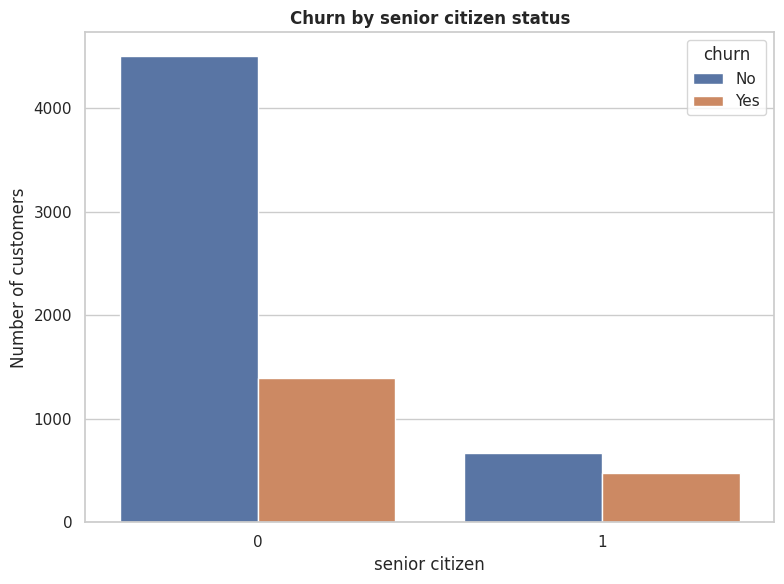

In [9]:
print('\n---Churn by Senior citizen')

fig, ax = plt.subplots(1,1, figsize=(8,6))
sns.countplot(data=df, x='seniorcitizen', hue='churn', ax=ax)
ax .set_xlabel('senior citizen')
ax.set_ylabel('Number of customers')
ax.set_title('Churn by senior citizen status',fontweight='bold')
plt.tight_layout()
plt.show()


 --- Taux de churn par contrat et methode de Paiment ---


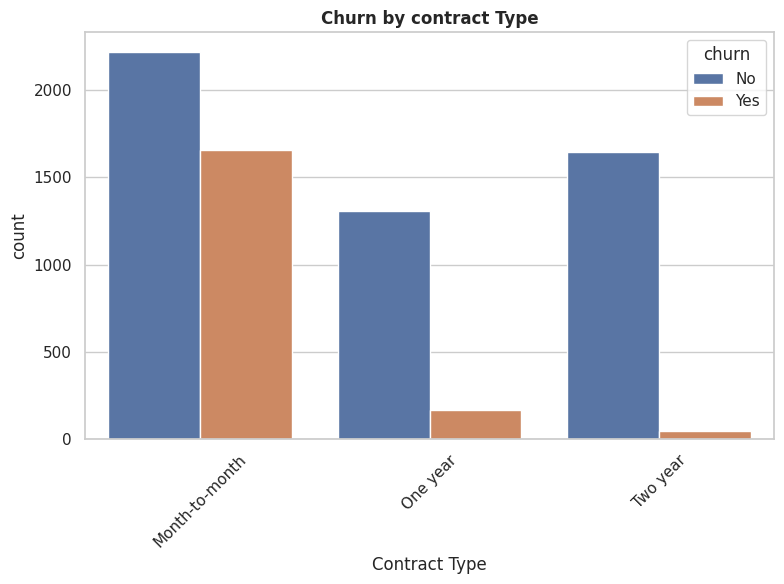

In [10]:
print('\n --- Taux de churn par contrat ---')

fig, ax = plt.subplots(1,1, figsize=(8,6))
sns.countplot(data=df, x='contract', hue='churn', ax=ax)
ax .set_xlabel('Contract Type')
ax.tick_params(axis='x', rotation=45)
ax.set_title('Churn by contract Type',fontweight='bold')
plt.tight_layout()
plt.show()


 --- Taux de churn par methode de paiment ---


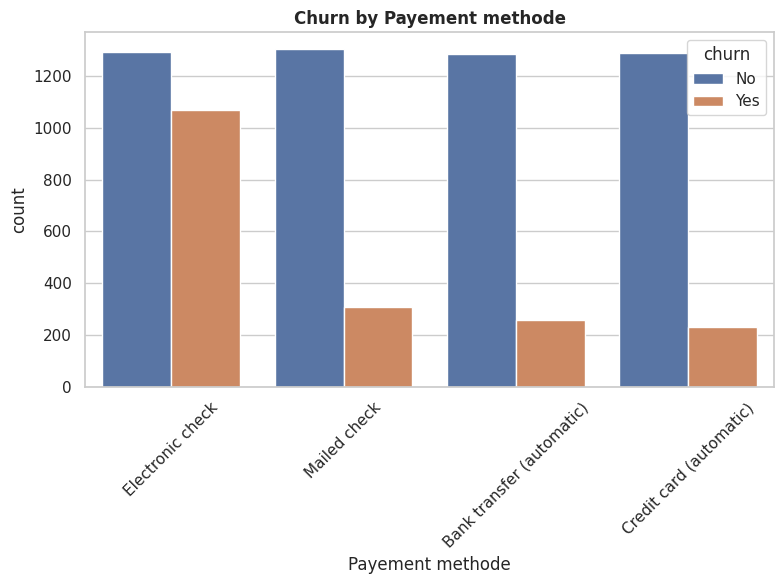

In [12]:
print('\n --- Taux de churn par methode de paiment ---')

fig, ax = plt.subplots(1,1, figsize=(8,6))
sns.countplot(data=df, x='paymentmethod', hue='churn', ax=ax)
ax .set_xlabel('Payement methode')
ax.tick_params(axis='x', rotation=45)
ax.set_title('Churn by Payement methode',fontweight='bold')
plt.tight_layout()
plt.show()

In [13]:
print("\n--- Statistiques par Segment d'Ancienneté et Type de Contrat ---")

# On calcule le taux de churn et la facture moyenne en croisant ancienneté et contrat
cross_analysis = df.groupby(['tenure_group', 'contract'], observed=False).agg(
    Churn_Rate=('churn', lambda x: (x == 'Yes').mean() * 100),
    Avg_Monthly_Charges=('monthlycharges', 'mean'),
    Customer_Count=('customerid', 'count')
).round(2)

print(cross_analysis)


--- Statistiques par Segment d'Ancienneté et Type de Contrat ---
                             Churn_Rate  Avg_Monthly_Charges  Customer_Count
tenure_group contract                                                       
0-12 months  Month-to-month       51.35                58.22            1994
             One year             10.48                35.80             124
             Two year              0.00                30.95              68
13-36 months Month-to-month       35.65                71.30            1223
             One year              8.05                52.27             447
             Two year              1.08                36.66             186
+37 months   Month-to-month       29.64                82.07             658
             One year             12.97                75.40             902
             Two year              3.19                65.29            1441
